# Chapter 2: A General Constrained-Optimization Method for Robust Beamforming

This notebook reproduces every figure of Chapter 2 of *Robust Adaptive Beamforming and Its Applications* (Ayman Elnashar, Wiley, forthcoming): Figures 2.1–2.8 and the timing Tables 2.3 and 2.4.

The chapter develops AS-SNC, a spectral active-set method for second-order cone programs with shared norm coupling,

$$\min_{\boldsymbol{w}}\ \boldsymbol{w}^{\mathrm{T}}\boldsymbol{Q}\boldsymbol{w}\quad\text{s.t.}\quad \boldsymbol{l}_i^{\mathrm{T}}\boldsymbol{w}\ \ge\ \nu_i\|\boldsymbol{w}\|+\beta_i,\qquad i=1,\dots,N,$$

with $\boldsymbol{Q}\succ 0$ and $\nu_i\ge 0$. AS-SNC computes one eigendecomposition of $\boldsymbol{Q}$, reduces each working-set system to a small multiplier system and two scalar equations, applies a reduced Newton correction when the scalar iteration stalls, and returns a point only after a scaled KKT residual test on the input problem; otherwise the shared-epigraph conic model is solved and the result is labelled as a fallback (Algorithm 2.1).

**How the figures are produced.** The timing figures (2.1, 2.5, 2.6, 2.8) are drawn from the records of the measurement run behind the chapter, stored in `data/archived_run`; set `RERUN = True` below to measure everything again on this machine (about one minute; timings will differ, the solutions should not). The figures that describe the solver itself (2.2, 2.3, 2.4, 2.7) are deterministic: this notebook recomputes them with the same seeds and checks them against the archived records before drawing.

MOSEK needs a licence and Gurobi's free licence limits model size; solvers that are unavailable are skipped in a re-run.

## Configuration

In [1]:
import os, sys
os.environ.setdefault('OPENBLAS_NUM_THREADS', '1')   # one BLAS thread, as in the chapter
os.environ.setdefault('OMP_NUM_THREADS', '1')
sys.path.insert(0, os.path.abspath('..'))            # chapter folder, so `ch2assnc` imports without installation
RERUN = False                  # True: measure every experiment again on this machine
QUICK = False                  # with RERUN: reduced counts (smoke test)
FIGDIR = '../figures'          # relative to notebooks/
ARCHIVE = '../data/archived_run'

## Library

`ch2assnc.algorithms` holds AS-SNC, the scaled KKT residual report and the shared-epigraph conic model used by the baselines and by the independent reference; `ch2assnc.scenarios` the instance generator, the Fama–French data, the 50-asset allocation and one runner per experiment; `ch2assnc.figures` one function per chapter figure and the results summary.

In [2]:
import json
import numpy as np
from ch2assnc import as_snc, quality, conic_solve, random_instance
from ch2assnc import scenarios as S, figures as F
F.INLINE = True                                      # show each figure under its cell

if RERUN:
    rec = S.run_all(quick=QUICK)
    FIGDIR = '../figures_quick' if QUICK else '../figures_rerun'
    F.save_records(rec, os.path.join(FIGDIR, 'records'))
else:
    rec = F.load_records(ARCHIVE)
SUMMARY = F.summarize(rec)
print('records:', ', '.join(sorted(rec)))
print('run environment:', json.dumps(rec['environment']))

records: conditioning, environment, famafrench, pareto, portfolio, scaling, supplement
run environment: {"platform": "Linux-6.18.55-x86_64-with-glibc2.39", "python": "3.12.14", "numpy": "2.3.5", "cvxpy": "1.9.3", "disabled": {}, "blas_threads": 1, "mosek_version": [11, 2, 6]}


## A first example

One random instance with $M = 50$ and $N = 8$. The solution is compared with Clarabel solving the shared-epigraph conic model.

In [3]:
rng = np.random.default_rng(0)
M, N = 50, 8
Fm = rng.standard_normal((M, M))
Q = Fm @ Fm.T / M + 0.1 * np.eye(M)        # symmetric positive definite cost
L = rng.standard_normal((M, N))            # constraint directions
nu = np.full(N, 0.2)                       # uncertainty radii
beta = np.ones(N)                          # offsets

w, outer, active, info = as_snc(Q, L, nu, beta, tol=1e-9, return_info=True)
wc, _ = conic_solve(Q, L, nu, beta, 'CLARABEL', 1e-10)
print('method:', info['method'], '| outer iterations:', outer, '| active constraints:', [int(i) for i in active])
print('objective %.10f  (Clarabel %.10f)' % (info['objective'], wc @ Q @ wc))
print('residuals: primal %.1e, stationarity %.1e, complementarity %.1e'
      % (info['primal'], info['stationarity'], info['complementarity']))

method: AS-SNC | outer iterations: 1 | active constraints: [0, 1, 2, 3, 4, 5, 6, 7]
objective 0.2192912011  (Clarabel 0.2192912011)
residuals: primal 2.4e-12, stationarity 1.6e-12, complementarity 4.5e-13


### Checks: scalar closed form (Section 2.2.6) and a repelling fixed point (Section 2.4.2)

For $M = 1$, $Q = l = 1$ and $\beta = 1$ the solution is $w^\star = 1/(1-\nu)$ for $\nu < 1$, and the problem is infeasible for $\nu \ge 1$. The two-dimensional instance of Section 2.4.2 has the optimum $\boldsymbol{w}^\star = (1, 0)$ but a repelling fixed point of the scalar iteration; the residual test rejects the spectral candidate and the conic fallback returns the certified optimum.

In [4]:
for c in S.regression_checks():
    name = 'nu = %g' % c['radius'] if 'radius' in c else c['case']
    if 'w' in c:
        print('%-40s w = %-34s %-18s residual %.1e' % (name, np.round(c['w'], 10), c['method'], c['residual']))
    else:
        print('%-40s %s' % (name, c['status']))

nu = 0                                   w = [1.]                               AS-SNC             residual 0.0e+00
nu = 0.2                                 w = [1.25]                             AS-SNC             residual 1.4e-11
nu = 0.9                                 w = [10.]                              AS-SNC             residual 0.0e+00
nu = 0.99                                w = [100.]                             AS-SNC             residual 3.5e-16
nu = 1                                   infeasible, no point returned
nu = 1.1                                 infeasible, no point returned
repelling fixed point (Section 2.4.2)    w = [1. 0.]                            fallback:CLARABEL  residual 8.0e-09


## Figure 2.1 and Table 2.3: dimension sweep

$M = 25, 50, 100, 200, 400$; $N = 20$; $\kappa(\boldsymbol{Q}) = 10^3$; eight instances per $M$ from one generator (seed 0). Median end-to-end time: AS-SNC includes the eigendecomposition and the final check; the baselines include CVXPY model construction, canonicalization and the backend solve. The last columns give the mean optimal active-set size and the MOSEK-to-AS-SNC ratio.

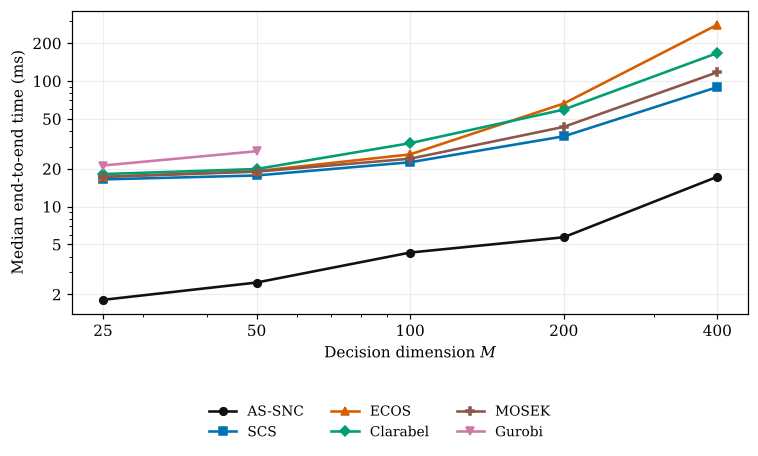

        M    AS-SNC       SCS      ECOS  Clarabel     MOSEK    Gurobi     |A|  MOSEK/AS-SNC
       25      1.81     16.48     17.29     18.17     17.23     21.26   12.75          9.52
       50      2.49     17.70     19.17     19.93     18.98     27.61   14.75          7.63
      100      4.31     22.57     26.06     32.01     24.08        --   16.50          5.59
      200      5.70     36.29     66.18     59.26     43.15        --   15.88          7.57
      400     17.29     89.43    280.68    166.98    117.41        --   17.50          6.79


In [5]:
F.fig_2_1(rec, FIGDIR)
COLS = ['AS-SNC', 'SCS', 'ECOS', 'Clarabel', 'MOSEK', 'Gurobi']

def print_table(table, head):
    print(f'{head:>9}' + ''.join(f'{c:>10}' for c in COLS) + f"{'|A|':>8}{'MOSEK/AS-SNC':>14}")
    for g, row in table.items():
        cells = ''.join(f"{row[c]['median_ms']:10.2f}" if row[c]['median_ms'] else f"{'--':>10}" for c in COLS)
        ratio = f"{row['MOSEK/AS-SNC']:14.2f}" if row['MOSEK/AS-SNC'] else f"{'--':>14}"
        print(f'{g:>9}' + cells + f"{row['mean_active_set']:8.2f}" + ratio)

print_table(SUMMARY['Table2.3_Fig2.1_dimension_sweep'], 'M')

## Figure 2.2: convergence of individual runs

Five instances (seed 20261020) with $M = 100$, $N = 20$, $\kappa(\boldsymbol{Q}) = 10^3$. Every recorded candidate, including Newton corrections, is evaluated by the scaled KKT residual of the input problem. The traces are recomputed here and compared with the archived run.

instance 1: candidates 7 (archived 7), outer iterations 6 (6), Newton steps 2 (2), final residual 3.2e-15 (3.0e-15)
instance 2: candidates 7 (archived 7), outer iterations 5 (5), Newton steps 3 (3), final residual 2.8e-12 (2.8e-12)
instance 3: candidates 9 (archived 9), outer iterations 8 (8), Newton steps 2 (2), final residual 2.1e-15 (1.9e-15)
instance 4: candidates 12 (archived 12), outer iterations 9 (9), Newton steps 5 (5), final residual 2.4e-14 (2.3e-14)
instance 5: candidates 13 (archived 13), outer iterations 10 (10), Newton steps 4 (4), final residual 3.0e-15 (3.0e-15)


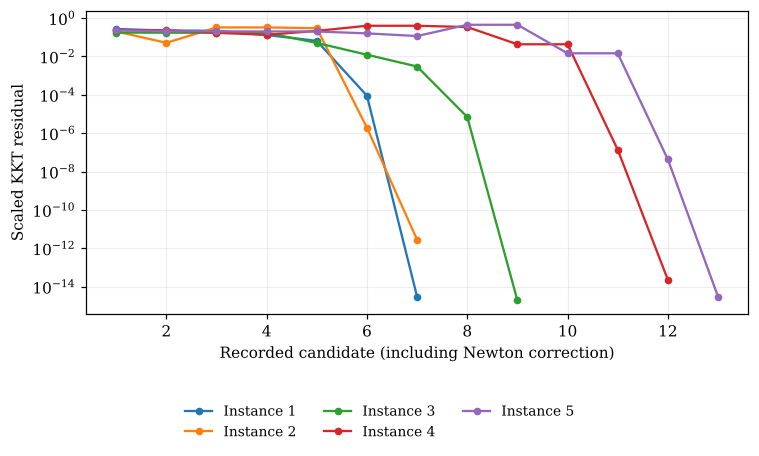

'../figures/Fig2_02_convergence.png'

In [6]:
live = S.convergence_traces()
for j, (a, b) in enumerate(zip(rec['supplement']['convergence'], live)):
    print(f"instance {j+1}: candidates {len(b['residuals'])} (archived {len(a['residuals'])}), "
          f"outer iterations {b['iterations']} ({a['iterations']}), Newton steps {b['newton_steps']} ({a['newton_steps']}), "
          f"final residual {b['residuals'][-1]:.1e} ({a['residuals'][-1]:.1e})")
F.fig_2_2(rec, FIGDIR)

## Figure 2.3: scaling of the cost matrix

Twenty instances (seed 2030) with $M = 100$, $N = 20$, $\kappa(\boldsymbol{Q}) = 10^3$. Each is solved with $\tau\boldsymbol{Q}$ for $\tau = 10^{-4}, \dots, 10^{4}$ and compared with the solution for $\tau = 1$.

largest relative change: recomputed 1.84e-14, archived 2.02e-14


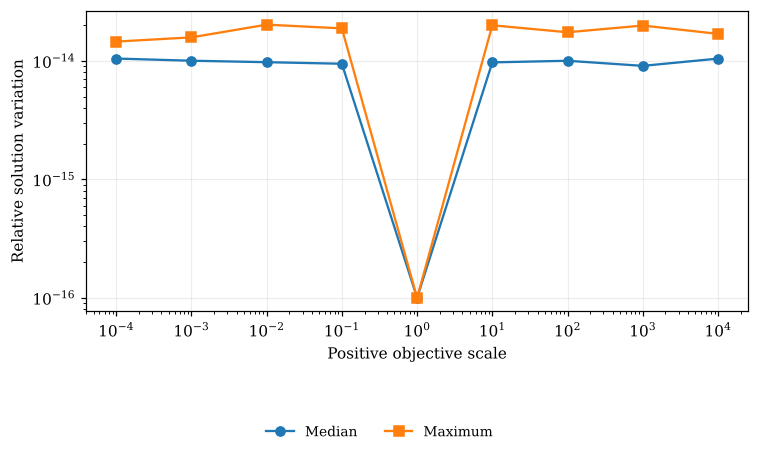

'../figures/Fig2_03_scale_invariance.png'

In [7]:
live = S.scale_invariance()
print('largest relative change: recomputed %.2e, archived %.2e'
      % (np.max(live['errors']), np.max(rec['supplement']['scale']['errors'])))
F.fig_2_3(rec, FIGDIR)

## Figure 2.4: active-set cardinality

Two hundred instances for each of $N = 20$ and $N = 50$ (seed 2040 + $N$) with $M = 100$ and $\kappa(\boldsymbol{Q}) = 10^3$.

N = 20: mean 15.21, identical to the archived counts: True
N = 50: mean 35.00, identical to the archived counts: True


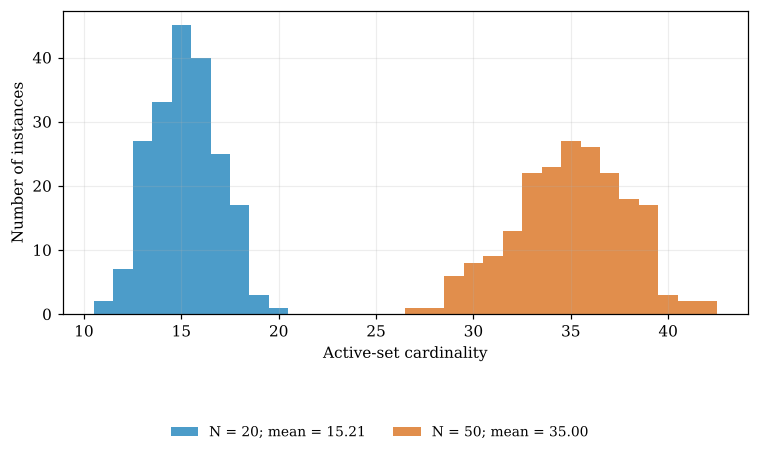

'../figures/Fig2_04_active_set_cardinality.png'

In [8]:
live = S.active_set_counts()
for N in ('20', '50'):
    print(f"N = {N}: mean {np.mean(live[N]):.2f}, identical to the archived counts: {live[N] == rec['supplement']['counts'][N]}")
F.fig_2_4(rec, FIGDIR)

## Figure 2.5: time versus accuracy

Eight instances (seed 10) with $M = 100$, $N = 20$, $\kappa(\boldsymbol{Q}) = 10^3$. Every solver is run at the requested tolerances $10^{-2}, 10^{-4}, \dots, 10^{-10}$. Left: median relative objective difference from the independent SCS reference (cross-checked with Clarabel). Right: median scaled feasibility violation on the constraints.

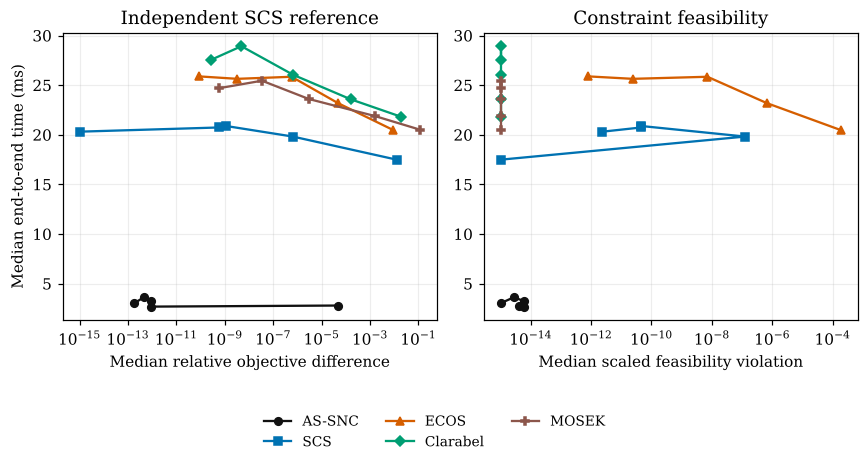

tol   0.01: AS-SNC 2.8 ms, 5e-05; SCS 17.5 ms, 1e-02; ECOS 20.5 ms, 9e-03; Clarabel 21.8 ms, 2e-02; MOSEK 20.5 ms, 1e-01
tol 0.0001: AS-SNC 2.7 ms, 9e-13; SCS 19.8 ms, 7e-07; ECOS 23.2 ms, 5e-05; Clarabel 23.6 ms, 2e-04; MOSEK 21.9 ms, 2e-03
tol  1e-06: AS-SNC 3.2 ms, 9e-13; SCS 20.9 ms, 1e-09; ECOS 25.8 ms, 6e-07; Clarabel 26.0 ms, 7e-07; MOSEK 23.6 ms, 3e-06
tol  1e-08: AS-SNC 3.6 ms, 5e-13; SCS 20.7 ms, 6e-10; ECOS 25.6 ms, 3e-09; Clarabel 28.9 ms, 5e-09; MOSEK 25.4 ms, 3e-08
tol  1e-10: AS-SNC 3.0 ms, 2e-13; SCS 20.3 ms, 0e+00; ECOS 25.9 ms, 8e-11; Clarabel 27.5 ms, 3e-10; MOSEK 24.7 ms, 6e-10


In [9]:
F.fig_2_5(rec, FIGDIR)
for tol, row in SUMMARY['Fig2.5_tolerance_sweep'].items():
    print(f'tol {tol:>6}: ' + '; '.join(f"{m} {v['median_ms']:.1f} ms, {v['median_relative_objective_difference']:.0e}"
                                         for m, v in row.items()))

## Figure 2.6: conditioning of the cost matrix

$M = 100$, $N = 20$; $\kappa(\boldsymbol{Q}) = 10, 10^2, \dots, 10^5$, ten instances each (seed 100 + 1000$k$).

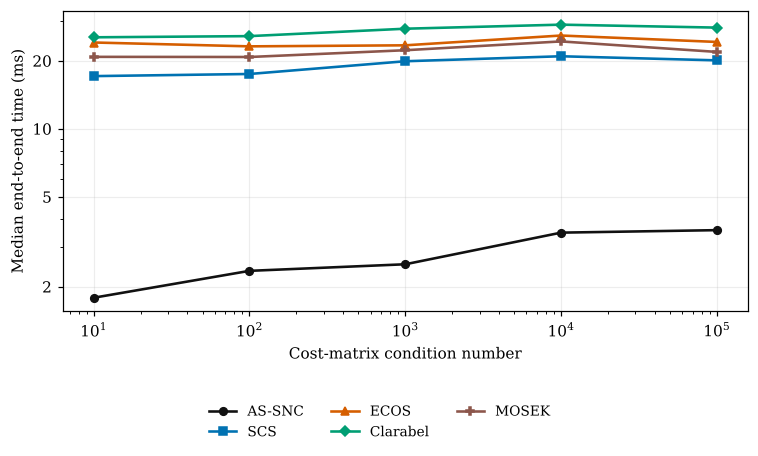

    kappa    AS-SNC       SCS      ECOS  Clarabel     MOSEK    Gurobi     |A|  MOSEK/AS-SNC
       10      1.79     17.11     24.10     25.42     20.82        --   15.60         11.66
      100      2.35     17.49     23.18     25.72     20.79        --   15.80          8.85
     1000      2.51     19.91     23.42     27.74     22.28        --   14.90          8.86
    10000      3.47     20.95     25.88     28.91     24.37        --   14.60          7.03
   100000      3.56     20.09     24.24     28.06     21.90        --   15.90          6.15


In [10]:
F.fig_2_6(rec, FIGDIR)
print_table(SUMMARY['Fig2.6_conditioning_sweep'], 'kappa')

## Figure 2.7: a 50-asset allocation

Three-factor covariance (seed 2050), five sectors of ten assets, expected-return floor 0.15 with zero radius, and sector-exposure floors 0.02 with a common radius $\kappa$ from 0 to 0.14. The sector floors are feasible only for $\kappa < 1/\sqrt{50}$ (vertical line). Every AS-SNC point is checked against a tight Clarabel solve. The sweep is recomputed here and compared with the archived run.

points: 29 | all from the spectral path: True
largest relative risk change vs archived run: 0.0e+00
largest relative objective difference to Clarabel: 1.7e-05
kappa 0.000: risk 0.0031, return 0.1500, ||w|| 0.21, |A| 3
kappa 0.020: risk 0.0032, return 0.1500, ||w|| 0.20, |A| 6
kappa 0.040: risk 0.0040, return 0.1846, ||w|| 0.24, |A| 5
kappa 0.060: risk 0.0052, return 0.2349, ||w|| 0.29, |A| 5
kappa 0.080: risk 0.0072, return 0.3189, ||w|| 0.38, |A| 5
kappa 0.100: risk 0.0115, return 0.4938, ||w|| 0.58, |A| 5
kappa 0.120: risk 0.0263, return 1.0890, ||w|| 1.25, |A| 5
kappa 0.140: risk 1.0780, return 13.5756, ||w|| 14.91, |A| 5


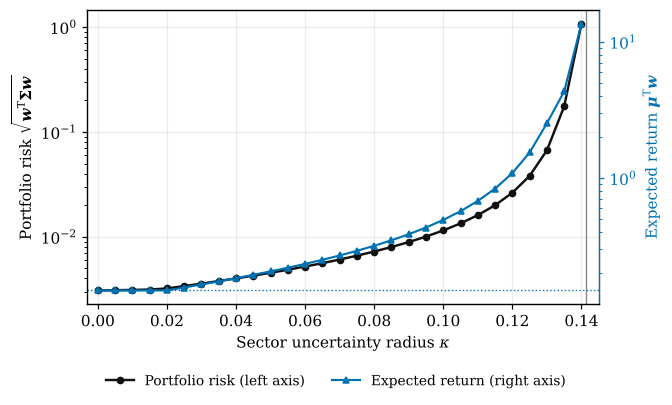

'../figures/Fig2_07_portfolio.png'

In [11]:
live = S.portfolio_sweep()
arch = rec['portfolio']
print('points:', len(live), '| all from the spectral path:', all(r['method'] == 'AS-SNC' for r in live))
print('largest relative risk change vs archived run: %.1e' % max(abs(a['risk'] - b['risk']) / a['risk'] for a, b in zip(arch, live)))
print('largest relative objective difference to Clarabel: %.1e' % max(r['rel_obj_diff'] for r in live))
for r in live[::4]:
    print(f"kappa {r['kappa']:.3f}: risk {r['risk']:.4f}, return {r['ret']:.4f}, ||w|| {r['norm']:.2f}, |A| {r['active']}")
F.fig_2_7(rec, FIGDIR)

## Figure 2.8 and Table 2.4: Fama–French problems

Monthly returns from the Kenneth R. French Data Library (as distributed with `linearmodels`), January 1949 to March 2017. FF-Ind12: the 12 industry portfolios; FF-All21: plus the 9 size–value portfolios; FF-All30: plus the 9 size–momentum portfolios. Each problem has a robust return floor and three group floors ($N = 4$); ten timed repetitions per problem.

FF-Ind12: 819 months x 12 portfolios, Jan 1949 to Mar 2017
FF-All21: 819 months x 21 portfolios, Jan 1949 to Mar 2017
FF-All30: 819 months x 30 portfolios, Jan 1949 to Mar 2017


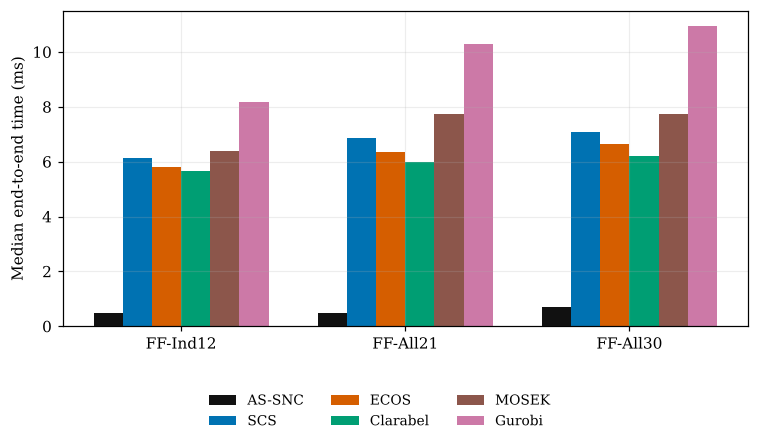

      set    AS-SNC       SCS      ECOS  Clarabel     MOSEK    Gurobi     |A|  MOSEK/AS-SNC
 FF-Ind12      0.48      6.14      5.79      5.64      6.39      8.17    3.00         13.27
 FF-All21      0.50      6.86      6.35      6.00      7.74     10.27    3.00         15.50
 FF-All30      0.68      7.07      6.63      6.22      7.74     10.95    3.00         11.32


In [12]:
for name in ('FF-Ind12', 'FF-All21', 'FF-All30'):
    df = S.load_ff(name)
    print(f'{name}: {df.shape[0]} months x {df.shape[1]} portfolios, {df.index.min():%b %Y} to {df.index.max():%b %Y}')
F.fig_2_8(rec, FIGDIR)
print_table(SUMMARY['Table2.4_Fig2.8_fama_french'], 'set')

## Supplementary: backend solve time and AS-SNC provenance

Median solve time measured by each backend, excluding CVXPY model construction and canonicalization; AS-SNC times stay end to end. Then the number of AS-SNC results that came from the spectral path and from the conic fallback in each timed experiment.

In [13]:
print(f"{'case':>9}" + ''.join(f'{c:>10}' for c in COLS))
for case, v in SUMMARY['supplementary_backend_solve_time_ms'].items():
    print(f'{case:>9}' + ''.join(f'{v[c]:10.2f}' if c in v else f"{'--':>10}" for c in COLS))
print()
for exp, counts in SUMMARY['provenance_of_AS-SNC_results'].items():
    print(f'{exp:>13}: {counts}')

     case    AS-SNC       SCS      ECOS  Clarabel     MOSEK    Gurobi
   M = 25      1.81      0.47      0.95      1.07      1.00      3.60
   M = 50      2.49      0.92      2.74      2.87      1.71      8.97
  M = 100      4.31      2.18      8.76     11.64      5.60        --
  M = 200      5.70      5.52     41.34     33.96     17.47        --
  M = 400     17.29     13.71    234.36    116.37     65.88        --
 FF-Ind12      0.48      0.45      0.12      0.16      0.52      1.06
 FF-All21      0.50      0.58      0.31      0.30      0.76      2.01
 FF-All30      0.68      0.98      0.40      0.59      0.79      2.97

      scaling: {'AS-SNC': 40}
 conditioning: {'AS-SNC': 50}
       pareto: {'AS-SNC': 40}
   famafrench: {'AS-SNC': 30}


## Results summary

Writes `results_summary.json` next to the figures (the same file as `scripts/generate_figures.py`).

In [14]:
SUMMARY['source'] = ('new run (reduced counts)' if QUICK else 'new run') if RERUN else 'archived run'
with open(os.path.join(FIGDIR, 'results_summary.json'), 'w') as fh:
    json.dump(SUMMARY, fh, indent=1, default=float)
print('written:', os.path.join(FIGDIR, 'results_summary.json'))

written: ../figures/results_summary.json
